# Анализ A/B-теста формы оплаты ЖКХ: EDA и проверка гипотез

 Единица наблюдения — пользователь в первой таблице и попытка оплаты во второй. Цель — проверить качество данных, описать аудиторию, прохождение этапов, повторные попытки и различия групп A/B. 

## Основные результаты

В выборке 1 500 пользователей и 2 661 попытка. Две попытки не связываются со справочником пользователей; у одной расходится группа. В основном анализе остаются 2 659 попыток: принадлежность к группе берётся из справочника пользователей. Конверсия попыток в успех: **49,77% в A и 64,40% в B**. Доля пользователей хотя бы с одним успехом: **65,73% и 80,40%**. По условию группы назначались по клиентам; статистическая проверка с этой единицей назначения приведена в разделе 12. При интерпретации считаем B новой формой, A — контрольной: явное соответствие букв вариантам в задании не указано, его нужно подтвердить перед внедрением.

## Контекст и допущения

- Отсутствующая дата последующего шага означает «достижение не зафиксировано», а не ошибку, которую нужно заполнять.
- Платёжный идентификатор трактуется как идентификатор попытки, а не подтверждённой финансовой транзакции.
- `users.group` принят за основной источник группы; ниже показана чувствительность к исключению спорной записи.
- Границы выгрузки и полнота наблюдения неизвестны; отсутствие финального события не доказывает окончательный отказ.
- Расчёты описательные. Повторные попытки одного пользователя зависимы. Основная проверка использует перестановку групп целиком по пользователям и кластерный bootstrap. Предполагается случайное назначение клиентов 1:1; условие сообщает о сплите по клиентам, но не раскрывает алгоритм рандомизации.


In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style='whitegrid', palette='colorblind', font='DejaVu Sans', font_scale=1.05)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 16)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
COLORS = {'A': "#27619F", 'B': '#C65E00'}
DATA_DIR = Path('.')
OUT = Path('results'); OUT.mkdir(exist_ok=True)
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
def show_fig(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

users_raw = pd.read_csv(DATA_DIR / 'users_clean.csv', sep=';')
payments_raw = pd.read_csv(DATA_DIR / 'payments_clean.csv', sep=';')
for filename in ['users_clean.csv', 'payments_clean.csv']:
    print(filename, 'SHA256:', hashlib.sha256((DATA_DIR / filename).read_bytes()).hexdigest())
print('Python:', sys.version.split()[0], 'pandas:', pd.__version__, 'numpy:', np.__version__)


users_clean.csv SHA256: 171f166ce39df3bd7d93ff027440c3e5e3a88537e67f75ec919e04420e442d40
payments_clean.csv SHA256: ab32eb9aa60fc12d97896917fc0a6937b847e9b04094188790dbebc097dce2c3
Python: 3.12.4 pandas: 2.2.2 numpy: 1.26.4


## 1. Структура и первичная проверка
Идентификаторы нужны для проверки ключей и объединения, но не рассматриваются как количественные характеристики. Примеры ниже не содержат идентификаторов.

In [2]:
for name, frame in [('Пользователи', users_raw), ('Попытки оплаты', payments_raw)]:
    print(name, frame.shape)
    display(frame.drop(columns=[c for c in ['user_id', 'payment_id'] if c in frame]).head())
    display(pd.DataFrame({'тип': frame.dtypes.astype(str), 'пропуски': frame.isna().sum(),
                          'пропуски, %': frame.isna().mean()*100, 'уникальных': frame.nunique()}))
    print('Полных дубликатов:', frame.duplicated().sum())
    text = frame.select_dtypes('object').apply(lambda s: s.astype('string').str.strip().str.lower())
    print('Текстовых маркеров пропуска:', text.isin(['', '-', 'нет информации', 'unknown', 'null', 'none', 'nan']).sum().to_dict())


Пользователи (1500, 5)


,group,age,city,device_type
0,A,31,Москва,ios
1,A,31,Москва,ios
2,A,25,Москва,android
3,A,20,Москва,ios
4,A,34,Москва,ios


,тип,пропуски,"пропуски, %",уникальных
user_id,int64,0,0.000,1500
group,object,0,0.000,2
age,int64,0,0.000,40
city,object,0,0.000,3
device_type,object,0,0.000,2


Полных дубликатов: 0
Текстовых маркеров пропуска: {'group': 0, 'city': 0, 'device_type': 0}
Попытки оплаты (2661, 7)


,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,A,16.04.2024 06:06,16.04.2024 06:10,NaN,NaN
1,A,12.04.2024 07:38,12.04.2024 07:41,NaN,NaN
2,A,26.04.2024 20:03,26.04.2024 20:07,NaN,NaN
3,A,09.04.2024 16:02,NaN,NaN,NaN
4,A,04.04.2024 03:46,04.04.2024 03:54,04.04.2024 03:57,04.04.2024 04:02


,тип,пропуски,"пропуски, %",уникальных
payment_id,int64,0,0.000,2661
user_id,float64,1,0.038,1501
group,object,0,0.000,2
step1_opened,object,0,0.000,2578
step2_entered,object,405,15.220,2188
step3_confirmed,object,942,35.400,1675
step4_success,object,1139,42.803,1489


Полных дубликатов: 0
Текстовых маркеров пропуска: {'group': 0, 'step1_opened': 0, 'step2_entered': 0, 'step3_confirmed': 0, 'step4_success': 0}


Пропусков в характеристиках пользователей нет. В платежах отсутствует один `user_id`; пропуски в датах следующих этапов анализируются как незавершённость воронки. Полных дубликатов нет. Разделитель исходных CSV — точка с запятой.

## 2. Типы, ключи и логическая согласованность
Работаем с копиями; исходные таблицы сохраняются. Даты разбираются в явно заданном формате, поэтому ошибки преобразования можно отличить от исходных пропусков.

In [3]:
users = users_raw.copy()
payments = payments_raw.copy()
steps = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
labels = ['Открытие', 'Ввод данных', 'Подтверждение', 'Успех']
date_errors = {}
for col in steps:
    payments[col] = pd.to_datetime(payments_raw[col], format='%d.%m.%Y %H:%M', errors='coerce')
    date_errors[col] = int((payments_raw[col].notna() & payments[col].isna()).sum())
payments['user_id'] = payments['user_id'].astype('Int64')
print('Ошибки разбора дат:', date_errors)
print('Повторы user_id в справочнике:', users.user_id.duplicated().sum())
print('Повторы payment_id:', payments.payment_id.duplicated().sum())
print('Возраст вне 0–120:', (~users.age.between(0, 120)).sum())
joined = payments.merge(users, on='user_id', how='left', suffixes=('_payment', '_user'), validate='many_to_one', indicator=True)
joined['group_conflict'] = joined['_merge'].eq('both') & joined.group_payment.ne(joined.group_user)
checks = []
for prev, curr in zip(steps, steps[1:]):
    checks.append({'переход': prev+' → '+curr,
                   'следующий без предыдущего': int((payments[curr].notna() & payments[prev].isna()).sum()),
                   'обратный порядок времени': int((payments[curr] < payments[prev]).sum())})
display(pd.DataFrame(checks))
display(pd.DataFrame({'минимум': payments[steps].min(), 'максимум': payments[steps].max()}))
audit = pd.Series({'исходных попыток': len(payments), 'нет user_id': payments.user_id.isna().sum(),
                   'user_id не найден': (joined.user_id.notna() & joined['_merge'].eq('left_only')).sum(),
                   'конфликт группы': joined.group_conflict.sum(),
                   'пользователей без попыток': (~users.user_id.isin(payments.user_id)).sum()})
display(audit.to_frame('число'))
audit.to_csv(OUT/'quality_audit.csv', header=True)


Ошибки разбора дат: {'step1_opened': 0, 'step2_entered': 0, 'step3_confirmed': 0, 'step4_success': 0}
Повторы user_id в справочнике: 0
Повторы payment_id: 0
Возраст вне 0–120: 0


,переход,следующий без предыдущего,обратный порядок времени
0,step1_opened → step2_entered,0,0
1,step2_entered → step3_confirmed,0,0
2,step3_confirmed → step4_success,0,0


,минимум,максимум
step1_opened,2024-04-01 00:19:00,2024-04-30 23:17:00
step2_entered,2024-04-01 00:23:00,2024-04-30 23:20:00
step3_confirmed,2024-04-01 00:29:00,2024-04-30 23:25:00
step4_success,2024-04-01 00:33:00,2024-04-30 23:30:00


,число
исходных попыток,2661
нет user_id,1
user_id не найден,1
конфликт группы,1
пользователей без попыток,0


Уникальность ключей подтверждена. Найдена одна попытка с неизвестным пользователем, одна — без идентификатора и одна — с конфликтом A/B. Нарушений последовательности этапов и обратного порядка времени не обнаружено. 

## 3. Рабочая выборка и новые признаки
Две несвязанные попытки сохраняем отдельно в памяти и исключаем из анализа характеристик пользователей. Для одной спорной записи принимаем группу из справочника. Высокие значения автоматически не удаляются; пропуски этапов не заполняются.

In [4]:
unlinked = joined.loc[joined['_merge'].ne('both')].copy()
work = joined.loc[joined['_merge'].eq('both')].copy()
work['group'] = work['group_user']
work['success'] = work.step4_success.notna().astype(int)
work['date'] = work.step1_opened.dt.normalize()
work['hour'] = work.step1_opened.dt.hour
work['weekday'] = work.step1_opened.dt.dayofweek
for prev, curr, name in zip(steps, steps[1:], ['open_to_enter_min', 'enter_to_confirm_min', 'confirm_to_success_min']):
    work[name] = (work[curr] - work[prev]).dt.total_seconds()/60
work['total_success_min'] = (work.step4_success - work.step1_opened).dt.total_seconds()/60
users['age_band'] = pd.cut(users.age, bins=[0, 24, 34, 44, 54, np.inf], labels=['до 25', '25–34', '35–44', '45–54', '55+'])
work = work.merge(users[['user_id', 'age_band']], on='user_id', how='left', validate='many_to_one')
print('До:', len(payments), 'после:', len(work), 'исключено:', len(payments)-len(work))
print('Скорректировано групп:', work.group_conflict.sum())
assert len(work) == len(payments)-len(unlinked)
assert work.payment_id.is_unique and users.user_id.is_unique
assert not any(date_errors.values())
assert work.age_band.notna().all()


До: 2661 после: 2659 исключено: 2
Скорректировано групп: 1


## 4. Состав пользователей и сопоставимость групп
Считаем аудиторию на уровне уникальных пользователей: повторные попытки не увеличивают вес человека при описании возраста, города и устройства.

,count,mean,std,min,25%,50%,75%,max
age,"1,500.000",32.699,7.795,20.000,27.000,33.000,38.000,60.000


group


,число,"доля, %"
group,,
A,750,50.000
B,750,50.000


city


,число,"доля, %"
city,,
Москва,594,39.600
Регион,513,34.200
СПб,393,26.200


device_type


,число,"доля, %"
device_type,,
android,775,51.667
ios,725,48.333


age_band


,число,"доля, %"
age_band,,
25–34,620,41.333
35–44,506,33.733
до 25,268,17.867
45–54,100,6.667
55+,6,0.400


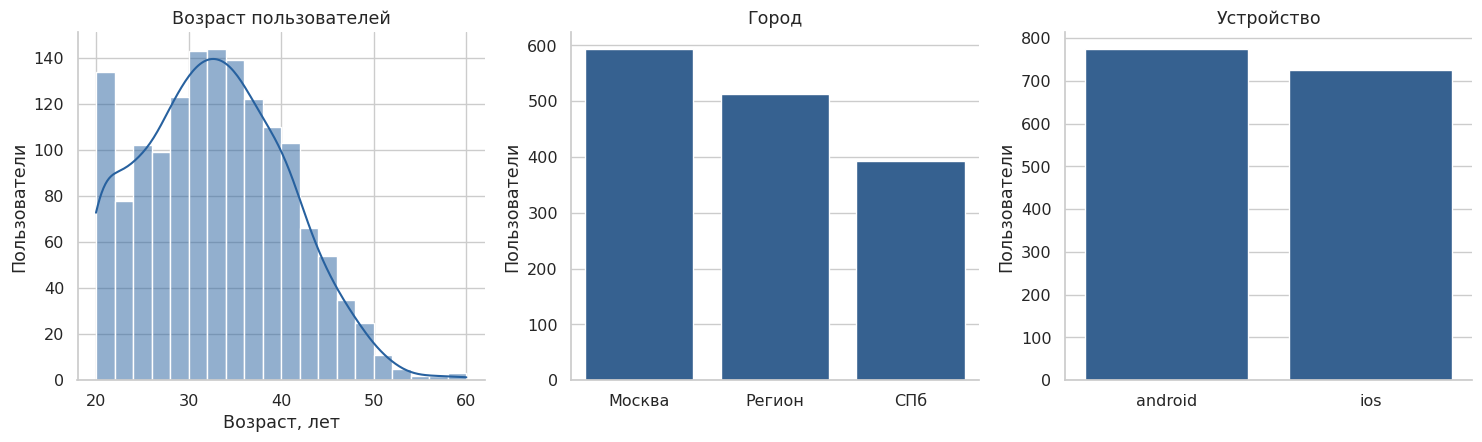

In [5]:
display(users[['age']].describe().T)
for col in ['group', 'city', 'device_type', 'age_band']:
    freq = users[col].value_counts(dropna=False).rename('число').to_frame()
    freq['доля, %'] = freq['число']/len(users)*100
    print(col); display(freq)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
sns.histplot(data=users, x='age', bins=20, kde=True, ax=axes[0], color=COLORS['A'])
axes[0].set(title='Возраст пользователей', xlabel='Возраст, лет', ylabel='Пользователи')
for ax, col, title in zip(axes[1:], ['city', 'device_type'], ['Город', 'Устройство']):
    sns.countplot(data=users, x=col, order=users[col].value_counts().index, color=COLORS['A'], ax=ax)
    ax.set(title=title, xlabel='', ylabel='Пользователи')
show_fig('audience')


,count,mean,median,std,min,max
group,,,,,,
A,750,32.744,32.000,7.820,20,60
B,750,32.655,33.000,7.775,20,60


city


city,Москва,Регион,СПб
group,,,
A,38.400,35.733,25.867
B,40.800,32.667,26.533


device_type


device_type,android,ios
group,,
A,54.133,45.867
B,49.200,50.800


age_band


age_band,до 25,25–34,35–44,45–54,55+
group,,,,,
A,16.533,43.333,32.000,7.600,0.533
B,19.200,39.333,35.467,5.733,0.267


Стандартизированная разница среднего возраста B−A: -0.011456632057666982


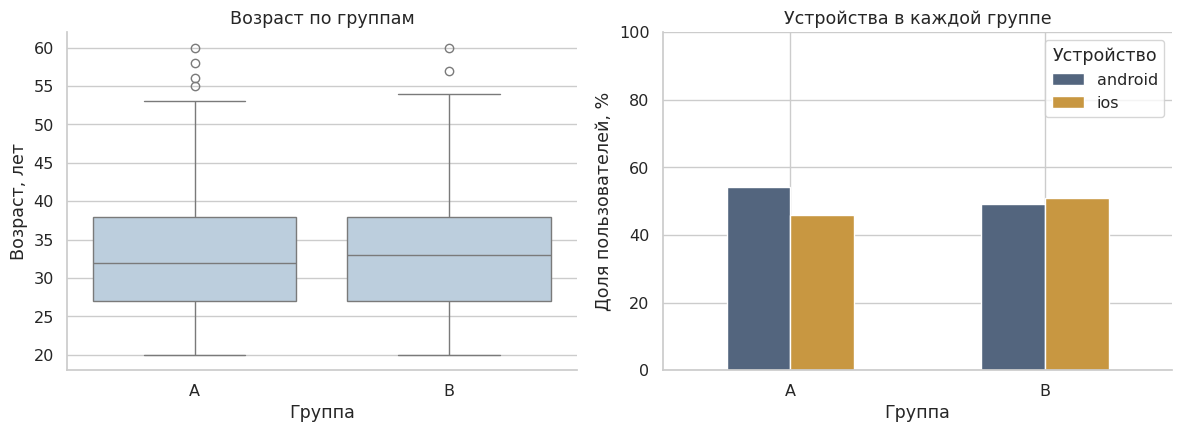

In [6]:
balance = users.groupby('group', observed=True).age.agg(['count', 'mean', 'median', 'std', 'min', 'max'])
display(balance)
for col in ['city', 'device_type', 'age_band']:
    print(col)
    display(pd.crosstab(users['group'], users[col], normalize='index')*100)
a = users.loc[users.group.eq('A'), 'age']; b = users.loc[users.group.eq('B'), 'age']
print('Стандартизированная разница среднего возраста B−A:', (b.mean()-a.mean())/np.sqrt((a.var()+b.var())/2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=users, x='group', y='age', order=['A','B'], ax=axes[0], color='#B6CFE2')
axes[0].set(title='Возраст по группам', xlabel='Группа', ylabel='Возраст, лет')
(pd.crosstab(users.group, users.device_type, normalize='index')*100).plot.bar(ax=axes[1], rot=0, color=['#53657E','#C89741'])
axes[1].set(title='Устройства в каждой группе', xlabel='Группа', ylabel='Доля пользователей, %', ylim=(0,100))
axes[1].legend(title='Устройство')
show_fig('group_balance')


В A и B по 750 пользователей. Средний возраст практически совпадает: 32,74 и 32,65 года. Устройства распределены неодинаково: Android — 54,13% в A и 49,20% в B. Поэтому различия конверсий полезно рассмотреть и внутри устройств. Сходство наблюдаемых характеристик не подтверждает рандомизацию и баланс ненаблюдаемых признаков.

## 5. Воронка попыток оплаты
Общая конверсия этапа — число попыток с датой этапа, делённое на число открытий. Переходная — число достигших этапа, делённое на число достигших предыдущего. Все попытки учитываются, включая повторные.

group,A,B
Открытие,1308,1351
Ввод данных,1061,1194
Подтверждение,758,960
Успех,651,870


group,A,B
"Доля от открытий, %",,
Открытие,100.000,100.000
Ввод данных,81.120,88.380
Подтверждение,57.950,71.060
Успех,49.770,64.400


group,A,B
"Переход от предыдущего этапа, %",,
Ввод данных,81.120,88.380
Подтверждение,71.440,80.400
Успех,85.880,90.620


group,A,B
"Не дошли до следующего этапа, попытки",,
Ввод данных,247.000,157.000
Подтверждение,303.000,234.000
Успех,107.000,90.000


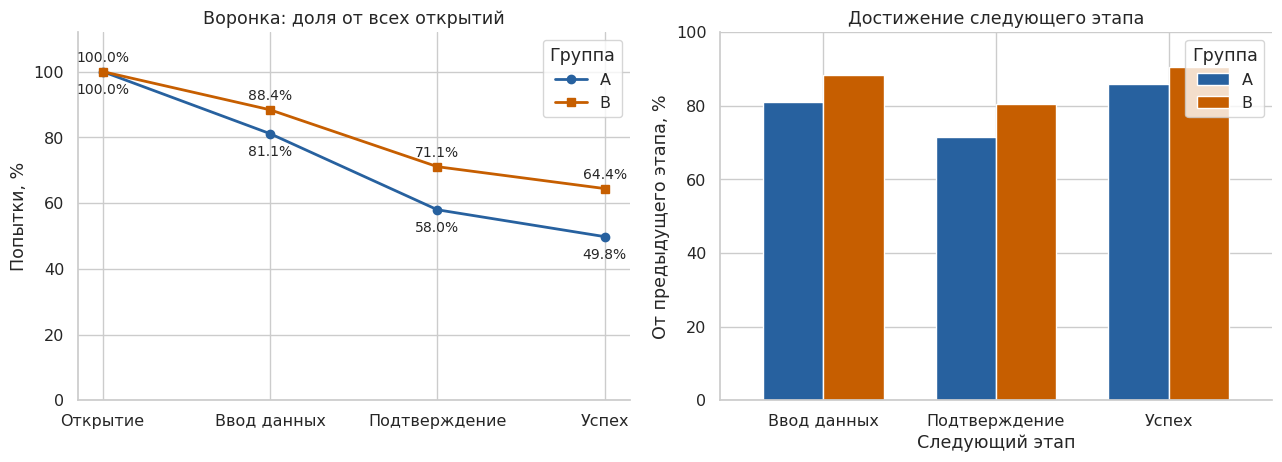

In [7]:
funnel = work.groupby('group')[steps].count().T
funnel.index = labels
display(funnel)
display((funnel.div(funnel.iloc[0])*100).round(2).rename_axis('Доля от открытий, %'))
transition = funnel.div(funnel.shift(1))*100
display(transition.iloc[1:].round(2).rename_axis('Переход от предыдущего этапа, %'))
losses = funnel.shift(1)-funnel
display(losses.iloc[1:].rename_axis('Не дошли до следующего этапа, попытки'))
funnel.to_csv(OUT/'funnel_counts.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for g, marker in [('A','o'), ('B','s')]:
    y = funnel[g]/funnel[g].iloc[0]*100
    axes[0].plot(labels, y, marker=marker, color=COLORS[g], label=g, linewidth=2)
    for i,v in enumerate(y): axes[0].annotate(f'{v:.1f}%', (i,v), xytext=(0,7 if g=='B' else -16), textcoords='offset points', ha='center', fontsize=10)
axes[0].set(title='Воронка: доля от всех открытий', ylabel='Попытки, %', ylim=(0,112))
axes[0].legend(title='Группа')
transition.iloc[1:].plot.bar(ax=axes[1], rot=0, color=COLORS, width=.7)
axes[1].set(title='Достижение следующего этапа', xlabel='Следующий этап', ylabel='От предыдущего этапа, %', ylim=(0,100))
axes[1].legend(title='Группа')
show_fig('funnel')


In [8]:
attempt_summary = work.groupby('group').success.agg(attempts='size', successful='sum', conversion='mean')
display(attempt_summary)
print('Разница B−A, п.п.:', (attempt_summary.loc['B','conversion']-attempt_summary.loc['A','conversion'])*100)
print('Наибольшее абсолютное выпадение:', losses.iloc[1:].sum(axis=1).idxmax())


,attempts,successful,conversion
group,,,
A,1308,651,0.498
B,1351,870,0.644


Разница B−A, п.п.: 14.626100951384974
Наибольшее абсолютное выпадение: Подтверждение


Конверсия попыток: A — 651/1 308 = 49,77%, B — 870/1 351 = 64,40%; разница 14,63 п.п. Наибольшее суммарное выпадение приходится на переход от ввода данных к подтверждению. Это указывает на участок для дальнейшей диагностики, но причины отказа и эффект интерфейса из этих таблиц не устанавливаются.

## 6. Повторные попытки и конверсия пользователей
Успешный пользователь — человек хотя бы с одним зафиксированным успехом за период. Знаменатель — все 750 пользователей соответствующей группы. Поскольку у всех есть попытки, это одновременно конверсия среди пользователей, начавших оплату, и среди пользователей данного файла; это не конверсия всего трафика продукта.

,users,successful_users,conversion,mean_attempts,median_attempts
group,,,,,
A,750,493,0.657,1.744,1.000
B,750,603,0.804,1.801,2.000


,пользователей
попыток,
1,739
2,443
3,238
4,80


group                 A       B
attempts  count 750.000 750.000
          mean    1.744   1.801
          std     0.897   0.906
          min     1.000   1.000
          25%     1.000   1.000
          50%     1.000   2.000
          75%     2.000   2.000
          max     4.000   4.000
successes count 750.000 750.000
          mean    0.868   1.160
          std     0.773   0.840
          min     0.000   0.000
          25%     0.000   1.000
          50%     1.000   1.000
          75%     1.000   2.000
          max     4.000   4.000

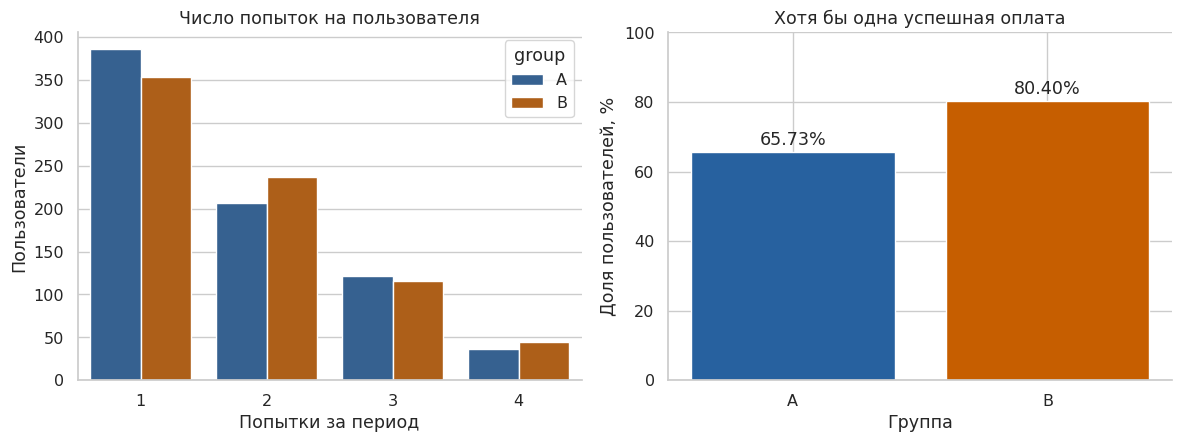

In [9]:
per_user = work.groupby('user_id').agg(attempts=('payment_id','size'), successes=('success','sum'),
    any_success=('success','max'), first_open=('step1_opened','min'), last_open=('step1_opened','max'))
user_work = users.merge(per_user, on='user_id', how='left', validate='one_to_one')
user_summary = user_work.groupby('group').agg(users=('user_id','size'), successful_users=('any_success','sum'),
    conversion=('any_success','mean'), mean_attempts=('attempts','mean'), median_attempts=('attempts','median'))
display(user_summary)
display(user_work.attempts.value_counts().sort_index().rename_axis('попыток').to_frame('пользователей'))
display(user_work.groupby('group')[['attempts','successes']].describe().T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
sns.countplot(data=user_work, x='attempts', hue='group', hue_order=['A','B'], palette=COLORS, ax=axes[0])
axes[0].set(title='Число попыток на пользователя', xlabel='Попытки за период', ylabel='Пользователи')
rates = user_summary.conversion*100
axes[1].bar(rates.index, rates, color=[COLORS[g] for g in rates.index])
for i,v in enumerate(rates): axes[1].text(i,v+2,f'{v:.2f}%',ha='center')
axes[1].set(title='Хотя бы одна успешная оплата', xlabel='Группа', ylabel='Доля пользователей, %', ylim=(0,100))
show_fig('user_conversion')
user_summary.to_csv(OUT/'user_summary.csv')


В A хотя бы один успех есть у 493 из 750 пользователей (65,73%), в B — у 603 из 750 (80,40%). Разница — 14,67 п.п. Показатель выше конверсии отдельных попыток, поскольку человек может завершить оплату после предыдущей неудачи. Разное число попыток и длительность доступного наблюдения могут влиять на сравнение.

## 7. Длительность этапов, асимметрия и выбросы
Интервалы рассчитываются только при наличии обеих дат. Общее время до успеха характеризует завершённые попытки; оно не измеряет время ожидания пользователей, не дошедших до финала. Минутная точность дат ограничивает детализацию.

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
open_to_enter_min,"2,255.000",2.395,1.864,1.000,1.000,1.000,3.000,5.000,6.000,8.000,13.000
enter_to_confirm_min,"1,718.000",4.488,1.924,1.000,3.000,4.000,6.000,7.000,8.000,9.000,11.000
confirm_to_success_min,"1,521.000",5.478,1.059,1.000,5.000,6.000,6.000,7.000,7.000,8.000,9.000
total_success_min,"1,521.000",12.382,2.809,5.000,10.000,12.000,14.000,16.000,17.000,20.000,24.000


open_to_enter_min              enter_to_confirm_min               \
                  count  mean median                count  mean median   
group                                                                    
A                  1061 2.356  1.000                  758 4.557  4.000   
B                  1194 2.429  1.000                  960 4.433  4.000   

      confirm_to_success_min              total_success_min                
                       count  mean median             count   mean median  
group                                                                      
A                        651 5.481  6.000               651 12.419 12.000  
B                        870 5.476  6.000               870 12.354 12.000

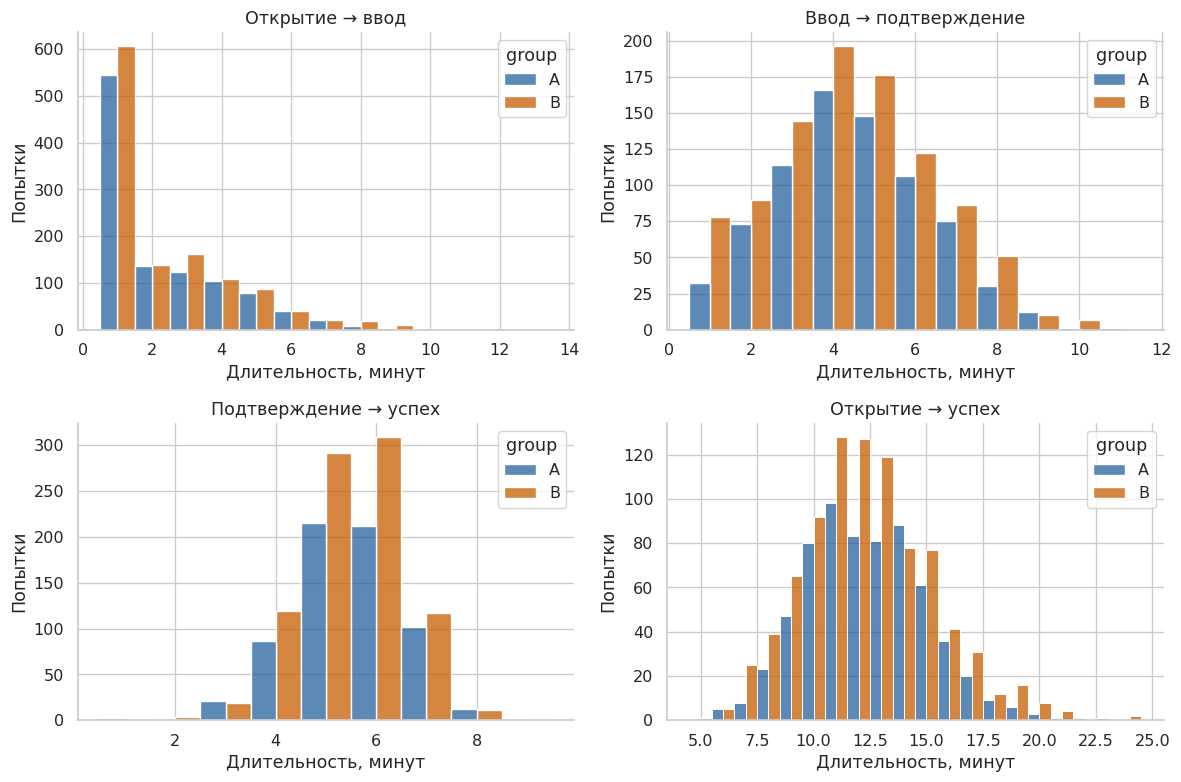

In [10]:
duration_cols = ['open_to_enter_min', 'enter_to_confirm_min', 'confirm_to_success_min', 'total_success_min']
duration_names = ['Открытие → ввод', 'Ввод → подтверждение', 'Подтверждение → успех', 'Открытие → успех']
display(work[duration_cols].describe(percentiles=[.25,.5,.75,.9,.95,.99]).T)
display(work.groupby('group')[duration_cols].agg(['count','mean','median']))
fig, axes = plt.subplots(2,2,figsize=(12,8))
for ax,col,title in zip(axes.flat,duration_cols,duration_names):
    sns.histplot(data=work, x=col, hue='group', hue_order=['A','B'], palette=COLORS, multiple='dodge', discrete=True, ax=ax)
    ax.set(title=title, xlabel='Длительность, минут', ylabel='Попытки')
show_fig('durations')


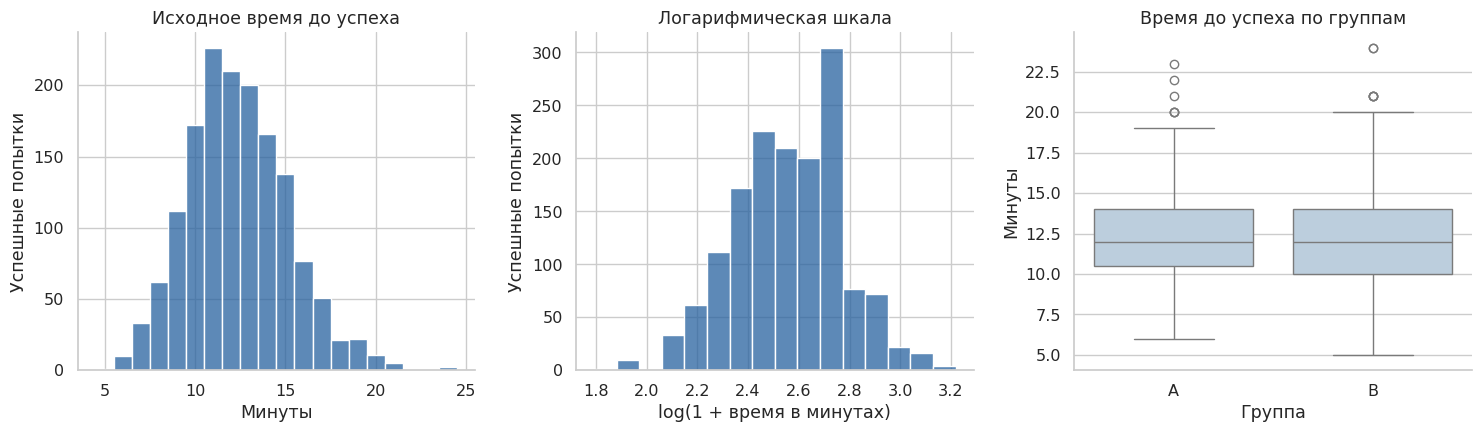

,асимметрия
open_to_enter_min,1.435
enter_to_confirm_min,0.201
confirm_to_success_min,-0.230
total_success_min,0.436


Наблюдений за границами 1,5 IQR: 9


In [11]:
# Исходная величина сохранена; преобразование рассматриваем как диагностику.
work['log_total_success_min'] = np.log1p(work.total_success_min)
fig, axes = plt.subplots(1,3,figsize=(15,4.5))
sns.histplot(data=work, x='total_success_min', discrete=True, ax=axes[0], color=COLORS['A'])
axes[0].set(title='Исходное время до успеха', xlabel='Минуты', ylabel='Успешные попытки')
sns.histplot(data=work, x='log_total_success_min', bins=16, ax=axes[1], color=COLORS['A'])
axes[1].set(title='Логарифмическая шкала', xlabel='log(1 + время в минутах)', ylabel='Успешные попытки')
sns.boxplot(data=work, x='group', y='total_success_min', ax=axes[2], color='#B6CFE2')
axes[2].set(title='Время до успеха по группам', xlabel='Группа', ylabel='Минуты')
show_fig('log_and_outliers')
display(work[duration_cols].skew().to_frame('асимметрия'))
q1,q3 = work.total_success_min.quantile([.25,.75]); iqr=q3-q1
print('Наблюдений за границами 1,5 IQR:', ((work.total_success_min<q1-1.5*iqr)|(work.total_success_min>q3+1.5*iqr)).sum())


Среди 1 521 успешной попытки среднее время от открытия до успеха — 12,38 минуты, медиана — 12 минут; центральные 50% лежат между 10 и 14 минутами. Медианы в A и B одинаковы — 12 минут. Первый переход заметно асимметричен: среднее 2,40 минуты при медиане 1 минута.

Логарифмирование показано для сравнения масштаба и формы распределения, а не как обязательная очистка. Нормальность после преобразования не предполагается. Ни одно наблюдение не удаляется по boxplot: крайнее значение само по себе не доказывает ошибку. Различия времени у успешных попыток нужно читать с учётом отбора по достижению этапа.

## 8. Конверсия по характеристикам пользователей
Доли считаются на уровне пользователей с указанием численности сегмента. Возраст сгруппирован в интервалы до 25, 25–34, 35–44, 45–54 и 55+. Малые сегменты дают нестабильные оценки; сегментные различия остаются описательными.

device_type


,device_type,group,users,successes,conversion,conversion_pct
0,android,A,406,262,0.645,64.532
1,android,B,369,295,0.799,79.946
2,ios,A,344,231,0.672,67.151
3,ios,B,381,308,0.808,80.840


city


,city,group,users,successes,conversion,conversion_pct
0,Москва,A,288,181,0.628,62.847
1,Москва,B,306,248,0.810,81.046
2,Регион,A,268,179,0.668,66.791
3,Регион,B,245,187,0.763,76.327
4,СПб,A,194,133,0.686,68.557
5,СПб,B,199,168,0.844,84.422


age_band


,age_band,group,users,successes,conversion,conversion_pct
0,до 25,A,124,88,0.710,70.968
1,до 25,B,144,120,0.833,83.333
2,25–34,A,325,212,0.652,65.231
3,25–34,B,295,239,0.810,81.017
4,35–44,A,240,151,0.629,62.917
5,35–44,B,266,210,0.789,78.947
6,45–54,A,57,39,0.684,68.421
7,45–54,B,43,32,0.744,74.419
8,55+,A,4,3,0.750,75.000
9,55+,B,2,2,1.000,100.000


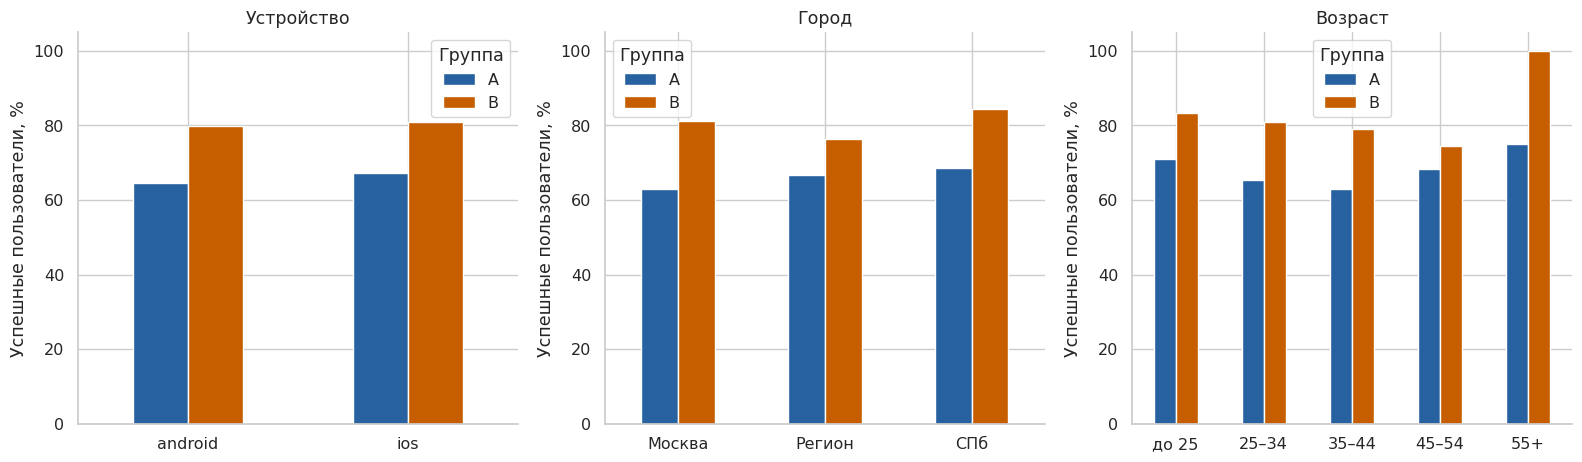

In [12]:
for col in ['device_type','city','age_band']:
    segments = user_work.groupby([col,'group'], observed=True).any_success.agg(users='size', successes='sum', conversion='mean').reset_index()
    segments['conversion_pct'] = segments.conversion*100
    print(col); display(segments)
    segments.to_csv(OUT/f'segments_{col}.csv',index=False)
fig,axes = plt.subplots(1,3,figsize=(16,4.8))
for ax,col,title in zip(axes,['device_type','city','age_band'],['Устройство','Город','Возраст']):
    tab=user_work.groupby([col,'group'],observed=True).any_success.mean().unstack()*100
    tab.plot.bar(ax=ax,rot=0,color=COLORS)
    ax.set(title=title,xlabel='',ylabel='Успешные пользователи, %',ylim=(0,105))
    ax.legend(title='Группа')
show_fig('segment_conversion')


В показанных разрезах устройств, городов и возрастных групп наблюдаемая конверсия пользователей B выше. В старшей возрастной категории особенно важно смотреть численность в таблице: высокая доля в малой группе не означает точную оценку для населения.

## 9. Временная динамика
Попытки привязаны к дню открытия. Конверсия дня — доля этих попыток с зафиксированным успехом, а не отношение разных потоков открытий и успехов в календарный день. Полнота наблюдения к концу периода не подтверждена.

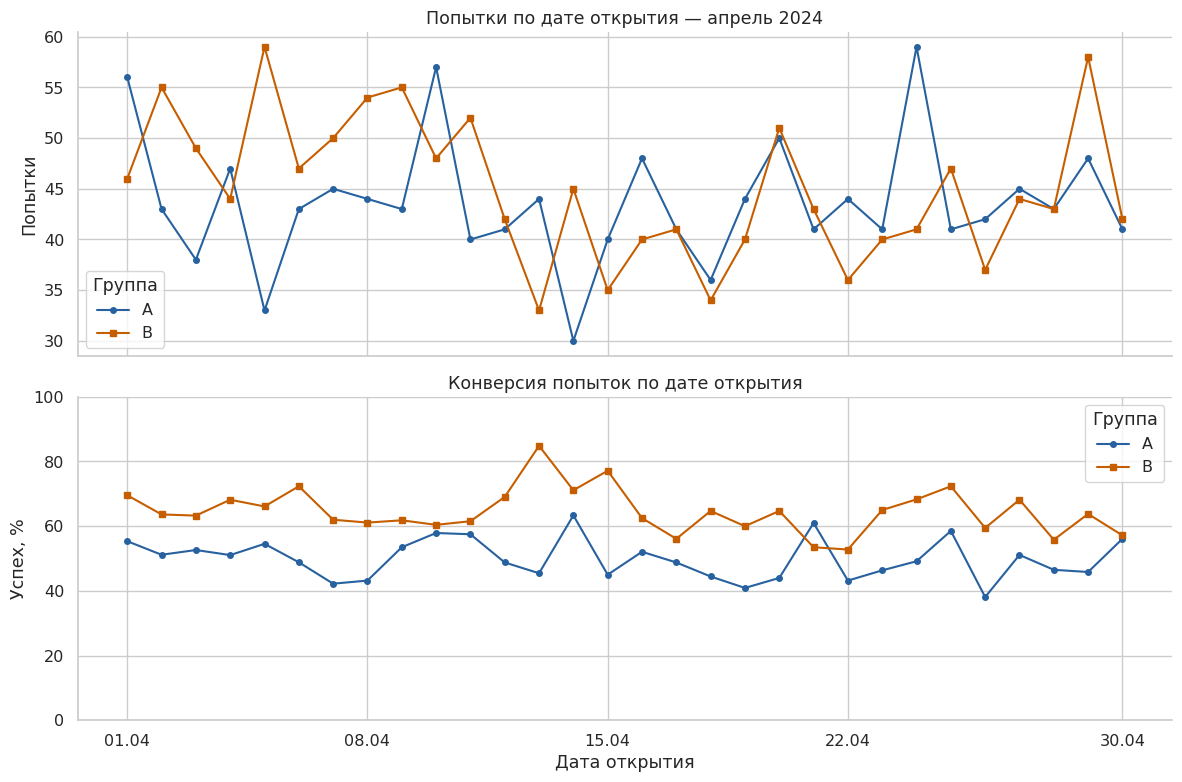

In [14]:
daily = work.groupby(['date','group']).agg(attempts=('payment_id','size'), successful=('success','sum'),conversion=('success','mean')).reset_index()
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True)
for g,marker in [('A','o'),('B','s')]:
    part=daily[daily.group.eq(g)]
    axes[0].plot(part.date,part.attempts,label=g,color=COLORS[g],marker=marker,markersize=4)
    axes[1].plot(part.date,part.conversion*100,label=g,color=COLORS[g],marker=marker,markersize=4)
axes[0].set(title='Попытки по дате открытия — апрель 2024',ylabel='Попытки')
axes[1].set(title='Конверсия попыток по дате открытия',ylabel='Успех, %',xlabel='Дата открытия',ylim=(0,100))
for ax in axes: ax.legend(title='Группа')
import matplotlib.dates as mdates
ticks=pd.to_datetime(['2024-04-01','2024-04-08','2024-04-15','2024-04-22','2024-04-30'])
axes[1].set_xticks(ticks); axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
show_fig('daily')
daily.to_csv(OUT/'daily.csv',index=False)


Один месяц позволяет описать колебания внутри выгрузки, но недостаточен для вывода о сезонности или долгосрочном тренде. Различия отдельных дней могут быть связаны с небольшими дневными знаменателями; причинные объяснения требуют дополнительных данных.

## 10. Чувствительность к спорным записям
Сравниваем исходные попытки, только связанные попытки с исходной группой платежа, основное решение с группой пользователя и исключение конфликта. У сценариев разные знаменатели; общая цель — проверить устойчивость описательного различия.

In [15]:
scenarios=[]
for name,frame,group_col in [
    ('Все исходные попытки; группа платежа',payments,'group'),
    ('Связанные; группа платежа',work,'group_payment'),
    ('Основной: связанные; группа пользователя',work,'group'),
    ('Исключить конфликт группы',work.loc[~work.group_conflict],'group')]:
    tmp=frame.assign(observed_success=frame.step4_success.notna().astype(int))
    tab=tmp.groupby(group_col).observed_success.agg(n='size', successes='sum', rate='mean')
    scenarios.append({'сценарий':name,'попыток A':tab.loc['A','n'],'попыток B':tab.loc['B','n'],
        'конверсия A, %':tab.loc['A','rate']*100,'конверсия B, %':tab.loc['B','rate']*100,
        'разница B−A, п.п.':(tab.loc['B','rate']-tab.loc['A','rate'])*100})
sensitivity=pd.DataFrame(scenarios)
display(sensitivity)
sensitivity.to_csv(OUT/'sensitivity.csv',index=False)


,сценарий,попыток A,попыток B,"конверсия A, %","конверсия B, %","разница B−A, п.п."
0,Все исходные попытки; группа платежа,1309,1352,49.733,64.423,14.690
1,Связанные; группа платежа,1307,1352,49.732,64.423,14.691
2,Основной: связанные; группа пользователя,1308,1351,49.771,64.397,14.626
3,Исключить конфликт группы,1307,1351,49.732,64.397,14.665


## 11. Выводы и дальнейшая работа

1. Ключи таблиц уникальны; две попытки не связались с пользователями, одна имеет конфликт группы. Основные расчёты используют 2 659 связанных попыток с группой из справочника. Сценарии выше позволяют оценить влияние этого решения.
2. B имеет более высокую наблюдаемую конверсию и на уровне попыток, и на уровне пользователей. Проверка с учётом назначения групп по клиентам приведена в разделе 12; полноту событий и алгоритм сплита необходимо подтвердить.
3. Наиболее заметное суммарное выпадение — между вводом данных и подтверждением. Для объяснения нужны причины ошибок, логи и сведения о сценарии оплаты.
4. Пользователи совершают повторные попытки, поэтому анализ попыток и анализ людей отвечают на разные вопросы. Для оценки A/B нужно учитывать уровень назначения группы.
5. Возраст групп близок, доли устройств различаются. Сегментные результаты следует читать вместе с размером сегментов; они не подтверждают причинное влияние устройства или возраста.

In [16]:
# Итоговые диагностические проверки, без изменения исходных данных.
assert len(user_work)==len(users)==1500
assert user_work.any_success.notna().all()
assert work.success.sum()==funnel.loc['Успех'].sum()
assert all((work[b].isna() | work[a].notna()).all() for a,b in zip(steps,steps[1:]))
assert (work[duration_cols].stack()>=0).all()
print('Сверки численности, воронки и интервалов выполнены.')


Сверки численности, воронки и интервалов выполнены.


## 12. Статистическая проверка A/B-теста

По условию: тест новой формы оплаты ЖКХ шёл 1–30 апреля 2024 года; группы назначались по клиентам. Основная метрика — доля попыток, дошедших от открытия формы до успешной оплаты. **B условно считается новой формой, A — контролем**.

**Гипотезы и метод.** H₀: конверсии попыток A и B равны; H₁: различаются. Для проверки равенства конверсий применён двусторонний перестановочный тест с перестановкой меток A/B на уровне пользователей. Статистика теста — разница конверсий попыток между группами. Все попытки одного пользователя сохранялись вместе. Используем двустороннюю проверку при α = 0,05: она позволяет обнаружить и ухудшение. Рост фиксируем при положительном эффекте и отклонении H₀.

Числитель метрики — сумма успешных попыток пользователей группы, знаменатель — сумма всех их открытий. Независимая единица назначения — клиент. Поэтому не применяем обычный z-тест к 2 659 попыткам как к независимым наблюдениям:

- Для интервала эффекта используем **20 000 кластерных bootstrap-выборок**: внутри каждой группы выбираем клиентов с возвращением и переносим все их попытки вместе. Пересчитываем отношение сумм, а не среднее персональных конверсий. 95% интервал — перцентили 2,5 и 97,5%.
- Для p-value используем **20 000 перестановок групп пользователей** с сохранением численности 750/750. Все попытки человека остаются вместе. Проверка валидна при обменности назначения клиентов по группам под нулевой гипотезой; без фактической рандомизации её причинная интерпретация не гарантируется. Monte Carlo p-value вычисляется с поправкой +1, поэтому не может быть нулевым.
- Доля людей хотя бы с одним успехом и конверсия первой попытки — дополнительные проверки устойчивости. Они не заменяют основную метрику задания. Сегментные сравнения остаются исследовательскими; отдельные подтверждающие тесты по множеству сегментов не проводятся.


In [17]:
from scipy import stats

# Данные по каждому клиенту — кластеру назначения группы.
cluster = user_work[['user_id','group','attempts','successes','any_success']].copy()
cluster['failure'] = cluster.attempts-cluster.successes
assert cluster.groupby('group').size().to_dict()=={'A':750,'B':750}
assert cluster[['attempts','successes']].notna().all().all()
assert work.step1_opened.ge(pd.Timestamp('2024-04-01')).all()
assert work.step1_opened.lt(pd.Timestamp('2024-05-01')).all()

# Проверка SRM при ожидаемом сплите 1:1.
sizes=cluster.groupby('group').size().reindex(['A','B'])
srm=stats.chisquare(sizes.to_numpy(),f_exp=[len(cluster)/2]*2)
print(f'SRM при сплите 1:1: χ²={srm.statistic:.3f}, p={srm.pvalue:.3f}')
print('Равная численность не доказывает корректность всех аспектов рандомизации.')

N_RESAMPLES=20_000
SEED=20241130
rng=np.random.default_rng(SEED)
arr={g:cluster.loc[cluster.group.eq(g),['successes','attempts','any_success']].to_numpy(dtype=float) for g in ['A','B']}
cr={g:arr[g][:,0].sum()/arr[g][:,1].sum() for g in ['A','B']}
effect=cr['B']-cr['A']
relative_lift=cr['B']/cr['A']-1
boot_delta=[];boot_user_delta=[]
for start in range(0,N_RESAMPLES,250):
    batch=min(250,N_RESAMPLES-start)
    sampled={g:arr[g][rng.integers(0,len(arr[g]),size=(batch,len(arr[g])))] for g in ['A','B']}
    rates={g:sampled[g][:,:,0].sum(axis=1)/sampled[g][:,:,1].sum(axis=1) for g in ['A','B']}
    user_rates={g:sampled[g][:,:,2].mean(axis=1) for g in ['A','B']}
    boot_delta.extend(rates['B']-rates['A'])
    boot_user_delta.extend(user_rates['B']-user_rates['A'])
ci=np.quantile(boot_delta,[.025,.975])
ci_user=np.quantile(boot_user_delta,[.025,.975])

all_clusters=cluster[['successes','attempts']].to_numpy(dtype=float)
totals=all_clusters.sum(axis=0)
perm_extreme=0
for _ in range(N_RESAMPLES):
    idx=rng.permutation(len(all_clusters))[:750]
    b_sum=all_clusters[idx].sum(axis=0);a_sum=totals-b_sum
    perm_effect=b_sum[0]/b_sum[1]-a_sum[0]/a_sum[1]
    perm_extreme+=int(abs(perm_effect)>=abs(effect)-1e-12)
perm_p=(perm_extreme+1)/(N_RESAMPLES+1)

ab_result=pd.DataFrame([{'метрика':'Успех / открытия попыток','A, %':cr['A']*100,'B, %':cr['B']*100,
    'эффект B−A, п.п.':effect*100,'95% ДИ: нижняя, п.п.':ci[0]*100,'95% ДИ: верхняя, п.п.':ci[1]*100,
    'относительный прирост, %':relative_lift*100,'p-value перестановок':perm_p}])
display(ab_result.T)
print('Перестановок не менее экстремальных, чем факт:',perm_extreme,'из',N_RESAMPLES)
print('Разрешение Monte Carlo p-value:',1/(N_RESAMPLES+1))
ab_result.to_csv(OUT/'ab_primary.csv',index=False)
display(Markdown(f'**Основная метрика:** A — {cr["A"]:.2%}, B — {cr["B"]:.2%}; '
    f'эффект **+{effect*100:.2f} п.п.**, относительный прирост **+{relative_lift*100:.2f}%**. '
    f'95% кластерный bootstrap-интервал: **[{ci[0]*100:.2f}; {ci[1]*100:.2f}] п.п.**; '
    f'двусторонний перестановочный p-value ≈ **{perm_p:.6f}**. '
    'Интервал не включает ноль, H₀ отвергается при α = 0,05. '
    'Monte Carlo p-value является оценкой с конечным разрешением, а не точным аналитическим значением.'))


SRM при сплите 1:1: χ²=0.000, p=1.000
Равная численность не доказывает корректность всех аспектов рандомизации.


,0
метрика,Успех / открытия попыток
"A, %",49.771
"B, %",64.397
"эффект B−A, п.п.",14.626
"95% ДИ: нижняя, п.п.",10.916
"95% ДИ: верхняя, п.п.",18.363
"относительный прирост, %",29.387
p-value перестановок,0.000


Перестановок не менее экстремальных, чем факт: 0 из 20000
Разрешение Monte Carlo p-value: 4.999750012499375e-05


**Основная метрика:** A — 49.77%, B — 64.40%; эффект **+14.63 п.п.**, относительный прирост **+29.39%**. 95% кластерный bootstrap-интервал: **[10.92; 18.36] п.п.**; двусторонний перестановочный p-value ≈ **0.000050**. Интервал не включает ноль, H₀ отвергается при α = 0,05. Monte Carlo p-value является оценкой с конечным разрешением, а не точным аналитическим значением.

### 12.1 Проверки на уровне пользователей
Первая попытка выбирается по времени открытия, при совпадении времени — по `payment_id`. Это даёт по одному наблюдению на клиента. Дополнительный z-тест для бинарного исхода «хотя бы один успех» использует независимость разных клиентов; предполагаем, что пользователи не влияют на исходы друг друга.

In [18]:
first_attempt=work.sort_values(['user_id','step1_opened','payment_id']).drop_duplicates('user_id')
first_summary=first_attempt.groupby('group').success.agg(n='size',successful='sum',conversion='mean')
display(first_summary)
user_rates=user_summary.conversion
pooled=user_summary.successful_users.sum()/user_summary.users.sum()
se=np.sqrt(pooled*(1-pooled)*(1/user_summary.loc['A','users']+1/user_summary.loc['B','users']))
z_user=(user_rates['B']-user_rates['A'])/se
p_user=2*stats.norm.sf(abs(z_user))
display(Markdown(f'Доля пользователей хотя бы с одним успехом: **{user_rates["A"]:.2%} → {user_rates["B"]:.2%}**; '
    f'разница **+{(user_rates["B"]-user_rates["A"])*100:.2f} п.п.**, '
    f'95% bootstrap-ДИ **[{ci_user[0]*100:.2f}; {ci_user[1]*100:.2f}] п.п.**; '
    f'двусторонний z-тест: p = {p_user:.3g}. '
    f'Конверсия первой попытки: **{first_summary.loc["A","conversion"]:.2%} → '
    f'{first_summary.loc["B","conversion"]:.2%}**.'))
first_summary.to_csv(OUT/'first_attempt_summary.csv')

# Описательная стандартизация состава устройств: одинаковые веса из всех 1 500 клиентов.
device_weights=users.device_type.value_counts(normalize=True)
device_cr=user_work.groupby(['device_type','group']).any_success.mean().unstack()
standardized=device_cr.mul(device_weights,axis=0).sum()
print('Конверсия пользователей при общих весах устройств:',(standardized*100).round(2).to_dict())
print('Стандартизированная разница B−A, п.п.:',(standardized['B']-standardized['A'])*100)
print('Это описательная проверка состава, а не новый подтверждающий тест.')


,n,successful,conversion
group,,,
A,750,381,0.508
B,750,493,0.657


Доля пользователей хотя бы с одним успехом: **65.73% → 80.40%**; разница **+14.67 п.п.**, 95% bootstrap-ДИ **[10.40; 19.07] п.п.**; двусторонний z-тест: p = 1.53e-10. Конверсия первой попытки: **50.80% → 65.73%**.

Конверсия пользователей при общих весах устройств: {'A': 65.8, 'B': 80.38}
Стандартизированная разница B−A, п.п.: 14.580006780178966
Это описательная проверка состава, а не новый подтверждающий тест.


### 12.2 Размер эффекта и неопределённость
Интервал относится к разнице долей успешных попыток и учитывает кластеризацию по клиентам. Он не отражает неопределённость из-за неизвестной полноты событий, нарушений фактической экспозиции или алгоритма распределения групп.

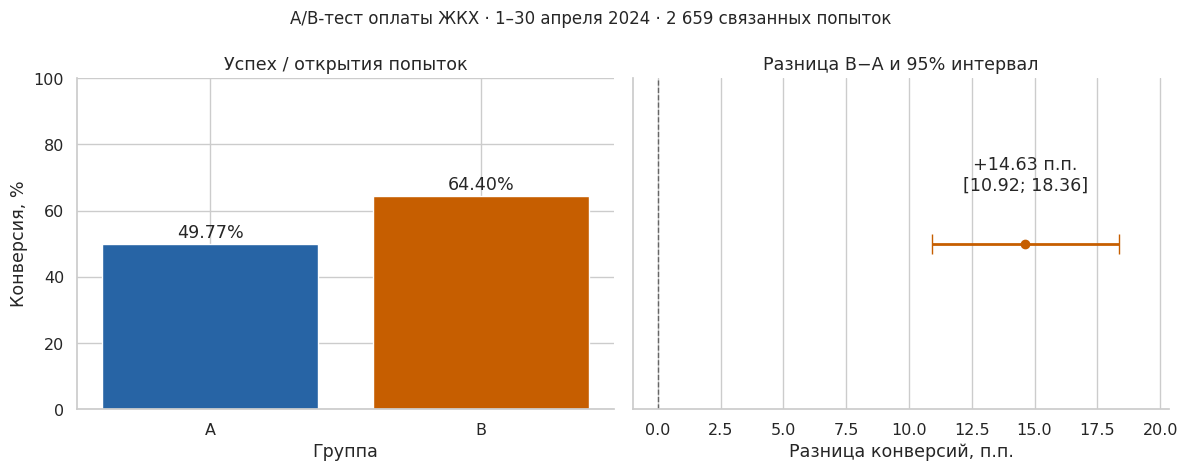

In [19]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
rate_values=np.array([cr['A'],cr['B']])*100
axes[0].bar(['A','B'],rate_values,color=[COLORS['A'],COLORS['B']])
for i,v in enumerate(rate_values):axes[0].text(i,v+2,f'{v:.2f}%',ha='center')
axes[0].set(title='Успех / открытия попыток',xlabel='Группа',ylabel='Конверсия, %',ylim=(0,100))
axes[1].errorbar(effect*100,0,xerr=np.array([[(effect-ci[0])*100],[(ci[1]-effect)*100]]),fmt='o',color=COLORS['B'],capsize=7,linewidth=2)
axes[1].axvline(0,color='#666666',linestyle='--',linewidth=1)
axes[1].set(title='Разница B−A и 95% интервал',xlabel='Разница конверсий, п.п.',yticks=[],xlim=(min(-1,ci[0]*100-2),ci[1]*100+2))
axes[1].text(effect*100,.08,f'+{effect*100:.2f} п.п.\n[{ci[0]*100:.2f}; {ci[1]*100:.2f}]',ha='center')
axes[1].set_ylim(-.25,.25)
fig.suptitle('A/B-тест оплаты ЖКХ · 1–30 апреля 2024 · 2 659 связанных попыток',fontsize=12)
show_fig('ab_effect')


## 13. Рекомендация продуктовой команде

**Рекомендую внедрять вариант с результатами B**, если подтверждено, что это новая форма. В предоставленной выборке он повышает ключевую конверсию из открытия в успешную оплату; кластерная проверка учитывает несколько попыток одного клиента. Положительное направление сохраняется на уровне пользователей, первой попытки и при разных способах обработки проблемных записей.

Рост примерно на 14,63 п.п. соответствует **около 146 дополнительным успехам на 1 000 открытий** при сопоставимом составе и поведении аудитории. Это перевод наблюдаемой разницы в понятный масштаб, а не прогноз абсолютного числа будущих оплат: форма может менять и число попыток.

**Почему запуск обоснован:** эффект статистически отличим от нуля, практически велик, не объясняется двумя несвязанными и одной спорной записью. По пользователям и в разрезах устройств направление совпадает. Медианное время успешной оплаты — 12 минут в обеих группах: доказанного ускорения всего процесса данные не показывают.

**Как внедрять:** расширять охват поэтапно с контролем конверсии и ошибок. До расширения подтвердить соответствие A/B вариантам, корректность назначения и фактического показа формы. При конфликте группы справочник принят за источник назначения, но проверить фактическую экспозицию по имеющимся полям невозможно.

В предоставленных данных нет финансовых сумм, технических причин отказа, ошибочных реквизитов, возвратов, обращений в поддержку и дублирующих списаний. Поэтому нельзя заключить, что все защитные метрики улучшились. При расширении охвата нужно отдельно отслеживать технические ошибки, корректность реквизитов и списаний, обращения и возвраты. Эти ограничения не отменяют положительный результат по целевой метрике.

Переходы между этапами помогают локализовать различия, но их знаменатели зависят от предыдущего поведения. Нельзя приписать каждый промежуточный сдвиг отдельному причинному эффекту без дополнительных проверок. Данные охватывают один месяц; переносимость на другие периоды не проверена.


In [19]:
assert ci[0]>0 and perm_p<.05
assert len(first_attempt)==len(users)
assert first_attempt.user_id.is_unique
assert sum(len(v) for v in arr.values())==1500
print('Основная метрика, пользовательские кластеры и дополнительные знаменатели сверены.')


Основная метрика, пользовательские кластеры и дополнительные знаменатели сверены.
